### IUST Deep Learning - HW1 - MLP

#### Import Libraries

In [61]:
import torch
import numpy as np
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_covtype
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from torch.utils.data import TensorDataset, DataLoader
device = "cuda" if torch.cuda.is_available() else "cpu" # I have GPU on my LapTop

#### Import and Check the Dataset

In [14]:
covtype = fetch_covtype()

In [15]:
covtype

{'data': array([[2.596e+03, 5.100e+01, 3.000e+00, ..., 0.000e+00, 0.000e+00,
         0.000e+00],
        [2.590e+03, 5.600e+01, 2.000e+00, ..., 0.000e+00, 0.000e+00,
         0.000e+00],
        [2.804e+03, 1.390e+02, 9.000e+00, ..., 0.000e+00, 0.000e+00,
         0.000e+00],
        ...,
        [2.386e+03, 1.590e+02, 1.700e+01, ..., 0.000e+00, 0.000e+00,
         0.000e+00],
        [2.384e+03, 1.700e+02, 1.500e+01, ..., 0.000e+00, 0.000e+00,
         0.000e+00],
        [2.383e+03, 1.650e+02, 1.300e+01, ..., 0.000e+00, 0.000e+00,
         0.000e+00]]),
 'target': array([5, 5, 2, ..., 3, 3, 3], dtype=int32),
 'frame': None,
 'target_names': ['Cover_Type'],
 'feature_names': ['Elevation',
  'Aspect',
  'Slope',
  'Horizontal_Distance_To_Hydrology',
  'Vertical_Distance_To_Hydrology',
  'Horizontal_Distance_To_Roadways',
  'Hillshade_9am',
  'Hillshade_Noon',
  'Hillshade_3pm',
  'Horizontal_Distance_To_Fire_Points',
  'Wilderness_Area_0',
  'Wilderness_Area_1',
  'Wilderness_Area_2',

In [16]:
covtype.data

array([[2.596e+03, 5.100e+01, 3.000e+00, ..., 0.000e+00, 0.000e+00,
        0.000e+00],
       [2.590e+03, 5.600e+01, 2.000e+00, ..., 0.000e+00, 0.000e+00,
        0.000e+00],
       [2.804e+03, 1.390e+02, 9.000e+00, ..., 0.000e+00, 0.000e+00,
        0.000e+00],
       ...,
       [2.386e+03, 1.590e+02, 1.700e+01, ..., 0.000e+00, 0.000e+00,
        0.000e+00],
       [2.384e+03, 1.700e+02, 1.500e+01, ..., 0.000e+00, 0.000e+00,
        0.000e+00],
       [2.383e+03, 1.650e+02, 1.300e+01, ..., 0.000e+00, 0.000e+00,
        0.000e+00]])

In [17]:
covtype.feature_names

['Elevation',
 'Aspect',
 'Slope',
 'Horizontal_Distance_To_Hydrology',
 'Vertical_Distance_To_Hydrology',
 'Horizontal_Distance_To_Roadways',
 'Hillshade_9am',
 'Hillshade_Noon',
 'Hillshade_3pm',
 'Horizontal_Distance_To_Fire_Points',
 'Wilderness_Area_0',
 'Wilderness_Area_1',
 'Wilderness_Area_2',
 'Wilderness_Area_3',
 'Soil_Type_0',
 'Soil_Type_1',
 'Soil_Type_2',
 'Soil_Type_3',
 'Soil_Type_4',
 'Soil_Type_5',
 'Soil_Type_6',
 'Soil_Type_7',
 'Soil_Type_8',
 'Soil_Type_9',
 'Soil_Type_10',
 'Soil_Type_11',
 'Soil_Type_12',
 'Soil_Type_13',
 'Soil_Type_14',
 'Soil_Type_15',
 'Soil_Type_16',
 'Soil_Type_17',
 'Soil_Type_18',
 'Soil_Type_19',
 'Soil_Type_20',
 'Soil_Type_21',
 'Soil_Type_22',
 'Soil_Type_23',
 'Soil_Type_24',
 'Soil_Type_25',
 'Soil_Type_26',
 'Soil_Type_27',
 'Soil_Type_28',
 'Soil_Type_29',
 'Soil_Type_30',
 'Soil_Type_31',
 'Soil_Type_32',
 'Soil_Type_33',
 'Soil_Type_34',
 'Soil_Type_35',
 'Soil_Type_36',
 'Soil_Type_37',
 'Soil_Type_38',
 'Soil_Type_39']

In [18]:
covtype.target

array([5, 5, 2, ..., 3, 3, 3], dtype=int32)

In [19]:
covtype.target_names

['Cover_Type']

In [20]:
covtype.data.max()

7173.0

In [21]:
covtype.data.min()

-173.0

#### Some Tiny Preprocesses

In [46]:
data = covtype.data
label = covtype.target

In [47]:
x_train, x_test, y_train, y_test = train_test_split(data, label, test_size=0.2, random_state=33)

In [48]:
x_train

array([[3053.,  222.,   12., ...,    0.,    0.,    0.],
       [3272.,  100.,   26., ...,    0.,    0.,    0.],
       [2538.,   92.,    6., ...,    0.,    0.,    0.],
       ...,
       [2502.,  358.,   56., ...,    0.,    0.,    0.],
       [3254.,  219.,   23., ...,    0.,    0.,    0.],
       [2774.,  127.,   26., ...,    0.,    0.,    0.]])

In [49]:
type(x_train)

numpy.ndarray

In [50]:
y_train.max()

7

In [51]:
y_train.min()

1

In [52]:
scaler = MinMaxScaler()                       
x_train = scaler.fit_transform(x_train)       
x_test  = scaler.transform(x_test)
x_test  = np.clip(x_test, 0, 1)  

In [53]:
# numpy to tensor conversion
x_train = torch.tensor(x_train, dtype=torch.float32)
x_test  = torch.tensor(x_test,  dtype=torch.float32)

y_train = torch.tensor(y_train - 1, dtype=torch.long)  # to use crossentropy
y_test  = torch.tensor(y_test  - 1, dtype=torch.long)

In [54]:
x_train

tensor([[0.5973, 0.6167, 0.1818,  ..., 0.0000, 0.0000, 0.0000],
        [0.7069, 0.2778, 0.3939,  ..., 0.0000, 0.0000, 0.0000],
        [0.3397, 0.2556, 0.0909,  ..., 0.0000, 0.0000, 0.0000],
        ...,
        [0.3217, 0.9944, 0.8485,  ..., 0.0000, 0.0000, 0.0000],
        [0.6978, 0.6083, 0.3485,  ..., 0.0000, 0.0000, 0.0000],
        [0.4577, 0.3528, 0.3939,  ..., 0.0000, 0.0000, 0.0000]])

In [55]:
type(x_train)

torch.Tensor

In [56]:
x_train[0]

tensor([0.5973, 0.6167, 0.1818, 0.0432, 0.2416, 0.2234, 0.8071, 0.9882, 0.7126,
        0.0151, 0.0000, 0.0000, 1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000])

In [57]:
len(x_train[0])

54

In [58]:
y_train.max()

tensor(6)

In [59]:
y_train.min()

tensor(0)

#### Create Model and DataLoader

In [60]:
train_loader = DataLoader(TensorDataset(x_train, y_train), batch_size=1024, shuffle=True)
test_loader  = DataLoader(TensorDataset(x_test,  y_test),  batch_size=4096)

In [62]:
class Model(nn.Module):
  def __init__(self, in_features=54, h1=512, h2=256, out_features=7):
    super().__init__()
    self.fc1 = nn.Linear(in_features, h1)
    self.fc2 = nn.Linear(h1, h2)
    self.out = nn.Linear(h2, out_features)

  def forward(self, x):
    x = F.relu(self.fc1(x))
    x = F.relu(self.fc2(x))
    x = self.out(x)
    return x

torch.manual_seed(42)
model = Model().to(device)

#### Loss Function and Optimizer

In [67]:
loss_f = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
epochs = 100

#### Training

##### Evaluate function to do "Validation" part on our test set 

In [68]:
def evaluate(loader):
    model.eval()
    correct = total = 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            correct += (model(xb).argmax(1) == yb).sum().item()
            total += yb.size(0)
    return correct / total

##### Train Model

In [69]:
train_losses, test_accs = [], []
for epoch in range(epochs):
    model.train()
    running = 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = loss_f(model(xb), yb)
        loss.backward()
        optimizer.step()
        running += loss.item() * xb.size(0)
    train_losses.append(running / len(train_loader.dataset))
    test_accs.append(evaluate(test_loader))
    print(f"Epoch {epoch+1}/{epochs}  loss={train_losses[-1]:.4f}  test acc={test_accs[-1]:.4f}")

Epoch 1/100  loss=0.6987  test acc=0.7371
Epoch 2/100  loss=0.5816  test acc=0.7598
Epoch 3/100  loss=0.5439  test acc=0.7721
Epoch 4/100  loss=0.5165  test acc=0.7788
Epoch 5/100  loss=0.4966  test acc=0.7860
Epoch 6/100  loss=0.4804  test acc=0.7829
Epoch 7/100  loss=0.4657  test acc=0.7951
Epoch 8/100  loss=0.4527  test acc=0.7987
Epoch 9/100  loss=0.4408  test acc=0.8113
Epoch 10/100  loss=0.4319  test acc=0.8185
Epoch 11/100  loss=0.4208  test acc=0.8207
Epoch 12/100  loss=0.4131  test acc=0.8296
Epoch 13/100  loss=0.4047  test acc=0.8307
Epoch 14/100  loss=0.3974  test acc=0.8355
Epoch 15/100  loss=0.3909  test acc=0.8280
Epoch 16/100  loss=0.3838  test acc=0.8350
Epoch 17/100  loss=0.3776  test acc=0.8387
Epoch 18/100  loss=0.3725  test acc=0.8411
Epoch 19/100  loss=0.3671  test acc=0.8368
Epoch 20/100  loss=0.3607  test acc=0.8492
Epoch 21/100  loss=0.3574  test acc=0.8456
Epoch 22/100  loss=0.3520  test acc=0.8460
Epoch 23/100  loss=0.3475  test acc=0.8580
Epoch 24/100  loss=0

#### Plot and Check Loss

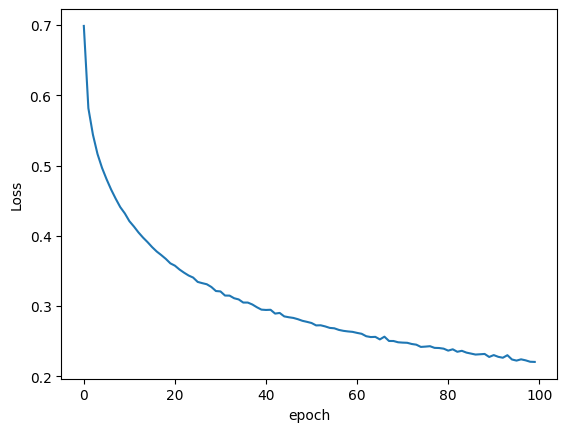

In [71]:
losses = torch.tensor(train_losses, dtype=torch.float)
plt.plot(range(epochs), losses)
#plt.xlim([50,100])
#plt.ylim([0,0.5])
plt.ylabel('Loss')
plt.xlabel('epoch')
plt.show()

In [73]:
x_test_d = x_test.to(device)
y_test_d = y_test.to(device)

model.eval()
with torch.no_grad():
    y_test_pred = model.forward(x_test_d)
    loss = loss_f(y_test_pred, y_test_d)
print(f'Test loss: {loss.item():.4f}')

Test loss: 0.2313


#### Final Evaluation and Saving best Model

In [74]:
correct = 0
with torch.no_grad():
    for i, data in enumerate(x_test_d):
        y_pred = model.forward(data)

        if i < 20:   # print only the first 20 samples
            print(f'{i+1}.) {y_pred.argmax().item()} {y_test_d[i].item()}')
        if y_pred.argmax().item() == y_test_d[i].item():
            correct += 1

print(f'\n{correct} out of {len(y_test_d)}  ->  {correct/len(y_test_d)*100:.2f}%')

1.) 1 0
2.) 1 1
3.) 1 1
4.) 2 2
5.) 0 0
6.) 1 1
7.) 0 0
8.) 0 0
9.) 1 1
10.) 2 2
11.) 0 0
12.) 1 1
13.) 0 0
14.) 1 1
15.) 0 0
16.) 1 1
17.) 1 1
18.) 1 1
19.) 2 2
20.) 1 1

105426 out of 116203  ->  90.73%


In [75]:
torch.save(model, 'covtype_model_v1.0.pt')

In [76]:
model = torch.load('covtype_model_v1.0.pt', weights_only=False, map_location=device)

In [77]:
model.eval()

Model(
  (fc1): Linear(in_features=54, out_features=512, bias=True)
  (fc2): Linear(in_features=512, out_features=256, bias=True)
  (out): Linear(in_features=256, out_features=7, bias=True)
)

#### Define, Train and Test a Better Model

In [78]:
"""
I have added batchnorm and dropout to make our performance better. 
(It is a practice, I think the approach is not good because overfit)
"""

class Model(nn.Module):
  def __init__(self, in_features=54, h1=1024, h2=512, h3=256, out_features=7, p=0.1):
    super().__init__()
    self.fc1 = nn.Linear(in_features, h1)
    self.bn1 = nn.BatchNorm1d(h1)
    self.fc2 = nn.Linear(h1, h2)
    self.bn2 = nn.BatchNorm1d(h2)
    self.fc3 = nn.Linear(h2, h3)
    self.bn3 = nn.BatchNorm1d(h3)
    self.out = nn.Linear(h3, out_features)
    self.drop = nn.Dropout(p)

  def forward(self, x):
    x = self.drop(F.relu(self.bn1(self.fc1(x))))
    x = self.drop(F.relu(self.bn2(self.fc2(x))))
    x = self.drop(F.relu(self.bn3(self.fc3(x))))
    return self.out(x)

torch.manual_seed(33)
model = Model().to(device)

In [79]:
loss_f = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
epochs = 100

In [80]:
train_losses, test_accs = [], []
for epoch in range(epochs):
    model.train()
    running = 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = loss_f(model(xb), yb)
        loss.backward()
        optimizer.step()
        running += loss.item() * xb.size(0)
    train_losses.append(running / len(train_loader.dataset))
    test_accs.append(evaluate(test_loader))
    print(f"Epoch {epoch+1}/{epochs}  loss={train_losses[-1]:.4f}  test acc={test_accs[-1]:.4f}")

Epoch 1/100  loss=0.5519  test acc=0.8175
Epoch 2/100  loss=0.4128  test acc=0.8501
Epoch 3/100  loss=0.3571  test acc=0.8685
Epoch 4/100  loss=0.3224  test acc=0.8855
Epoch 5/100  loss=0.2970  test acc=0.8969
Epoch 6/100  loss=0.2788  test acc=0.9008
Epoch 7/100  loss=0.2635  test acc=0.9060
Epoch 8/100  loss=0.2529  test acc=0.9114
Epoch 9/100  loss=0.2420  test acc=0.9138
Epoch 10/100  loss=0.2330  test acc=0.9163
Epoch 11/100  loss=0.2255  test acc=0.9214
Epoch 12/100  loss=0.2185  test acc=0.9233
Epoch 13/100  loss=0.2126  test acc=0.9236
Epoch 14/100  loss=0.2066  test acc=0.9281
Epoch 15/100  loss=0.2026  test acc=0.9296
Epoch 16/100  loss=0.1972  test acc=0.9302
Epoch 17/100  loss=0.1926  test acc=0.9320
Epoch 18/100  loss=0.1891  test acc=0.9332
Epoch 19/100  loss=0.1853  test acc=0.9349
Epoch 20/100  loss=0.1819  test acc=0.9354
Epoch 21/100  loss=0.1790  test acc=0.9368
Epoch 22/100  loss=0.1765  test acc=0.9367
Epoch 23/100  loss=0.1725  test acc=0.9388
Epoch 24/100  loss=0

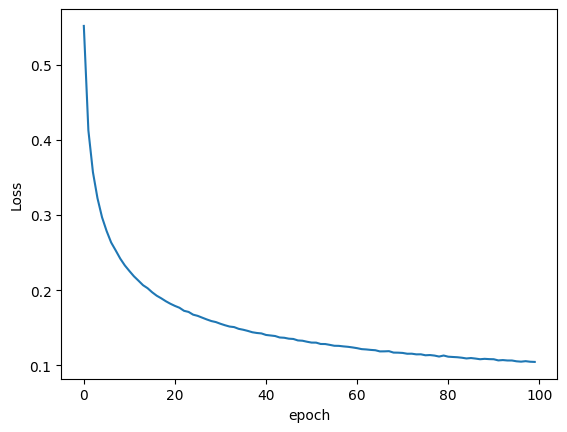

In [81]:
losses = torch.tensor(train_losses, dtype=torch.float)
plt.plot(range(epochs), losses)
#plt.xlim([50,100])
#plt.ylim([0,0.5])
plt.ylabel('Loss')
plt.xlabel('epoch')
plt.show()

In [82]:
x_test_d = x_test.to(device)
y_test_d = y_test.to(device)

model.eval()
with torch.no_grad():
    y_test_pred = model.forward(x_test_d)
    loss = loss_f(y_test_pred, y_test_d)
print(f'Test loss: {loss.item():.4f}')

Test loss: 0.1029


In [84]:
model.eval()
with torch.no_grad():
    preds = model(x_test_d).argmax(dim=1)
    correct = (preds == y_test_d).sum().item()

for i in range(20):
    print(f'{i+1}.) {preds[i].item()} {y_test_d[i].item()}')
print(f'\n{correct} out of {len(y_test_d)}  ->  {correct/len(y_test_d)*100:.2f}%')

1.) 0 0
2.) 1 1
3.) 1 1
4.) 2 2
5.) 0 0
6.) 1 1
7.) 0 0
8.) 0 0
9.) 1 1
10.) 2 2
11.) 0 0
12.) 1 1
13.) 0 0
14.) 1 1
15.) 0 0
16.) 1 1
17.) 0 1
18.) 1 1
19.) 2 2
20.) 1 1

111532 out of 116203  ->  95.98%


In [85]:
torch.save(model, 'covtype_model_v2.0.pt')

In [87]:
model = torch.load('covtype_model_v2.0.pt', weights_only=False, map_location=device)
model.eval()

Model(
  (fc1): Linear(in_features=54, out_features=1024, bias=True)
  (bn1): BatchNorm1d(1024, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (fc2): Linear(in_features=1024, out_features=512, bias=True)
  (bn2): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (fc3): Linear(in_features=512, out_features=256, bias=True)
  (bn3): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (out): Linear(in_features=256, out_features=7, bias=True)
  (drop): Dropout(p=0.1, inplace=False)
)